In [80]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib
import numpy as np
import scipy.optimize
import odrpack
import pandas as pd

plt.rcParams["figure.dpi"] = 150
plt.rcParams["text.usetex"] = True
plt.rcParams["font.size"] = 12


# matplotlib.rcParams['mathtext.fontset'] = 'stix'
# matplotlib.rcParams['font.family'] = 'Computer Modern'


plt.rcParams['font.family'] = 'serif' # or 'sans-serif' or 'monospace'
plt.rcParams['font.serif'] = 'cmr10'
plt.rcParams['font.sans-serif'] = 'cmss10'
plt.rcParams['font.monospace'] = 'cmtt10'
plt.rcParams["axes.formatter.use_mathtext"] = True # to fix the minus signs
%config InlineBackend.figure_format = 'retina'
plt.rcParams['axes.grid'] = True

In [81]:
def string_to_float_list(data_string: str):
    return np.array([float(x) for x in data_string.split()])

In [82]:
wavelength = 632.8e-9
wavevector = 2*np.pi / wavelength

container_width = 17.12e-3
glass_thickness = 3.12e-3

#gas_width = 9.64e-3
gas_width = container_width #- 2 * glass_thickness

print(gas_width * 1e3)

kpa_per_atm = 101.325

17.12


In [83]:
trial_2_pressures = string_to_float_list("""
0
12
21
28
36
44
52
70
""")

trial_2_intensities = string_to_float_list("""10.243 
23.630  
32.838  
30.861 
22.697 
10.004
16.500 
16.379
""")

trial_2_intensities_err = string_to_float_list("""
0.426
3.573
3.018
1.581
2.252
 0.340
1.190
0.756
 1.694
""")


trial_4_pressures = string_to_float_list("""
0
6
8
10
12
14
16
18
20
22
24
26
28
30
32
34
36
38
40
42
44
46
48
50.5
52
54
56
58
60
62
64
66
68
70
72
74
76
78
80
82
84
86
88
90
""")

trial_4_intensities = string_to_float_list("""
52.153
34.479
54.067
63.945
56.711
48.652
16.915
14.829
36.860
55.561
69.997
58.842
35.649
15.502
16.253
44.556
64.983
57.118
42.048
17.539
14.765
50.619
60.336
43.395
30.128
12.502
26.511
53.365
61.155
41.206
17.654
12.989
31.580
53.959
61.173
43.023
17.527
13.405
26.138
52.611
60.635
41.429
20.470
13.106
""")

trial_4_intensities_err = string_to_float_list("""
2.798
3.250
2.098
0.626
2.455
2.553
1.042
0.835
2.293
2.644
1.060
2.115
3.445
1.520
1.787
3.623
0.904
2.397
2.265
1.518
1.333
3.520
1.227
1.190
2.723
0.807
3.069
3.181
0.807
2.550
1.711
0.956
2.174
2.513
0.707
2.598
2.059
0.654
2.227
2.563
1.199
1.984
2.189
0.573
""")


trial_5_data = pd.read_csv("data/11-16-26_air_trial_5.csv")
trial_5_pressures = trial_5_data["Data Set 5:Pressure(kPa)"]
trial_5_intensities = trial_5_data["Data Set 5:Illumination(lux)"]

trial_6_data = pd.read_csv("data/11-16-26_air_trial_6.csv")
trial_6_pressures = trial_6_data["Data Set 1:Pressure(kPa)"]
trial_6_intensities = trial_6_data["Data Set 1:Illumination(lux)"]

trial_numbers = [2, 4, 5, 6]
trial_pressures = [trial_2_pressures, trial_4_pressures, trial_5_pressures, trial_6_pressures]
trial_intensities = [trial_2_intensities, trial_4_intensities, trial_5_intensities, trial_6_intensities]
trial_intensities_err = [trial_2_intensities_err, trial_4_intensities_err, np.zeros(len(trial_5_intensities)), np.zeros(len(trial_6_intensities))]




In [84]:
def fit_curve(P, I0, k, phi, C):
    n = 1 + k * P
    return I0  * np.cos((n * wavevector * gas_width + phi) / 2)**2 + C
    #return (I0 / 2) * np.cos(n * wavevector * gas_width + phi) + C

1.0003064405037816


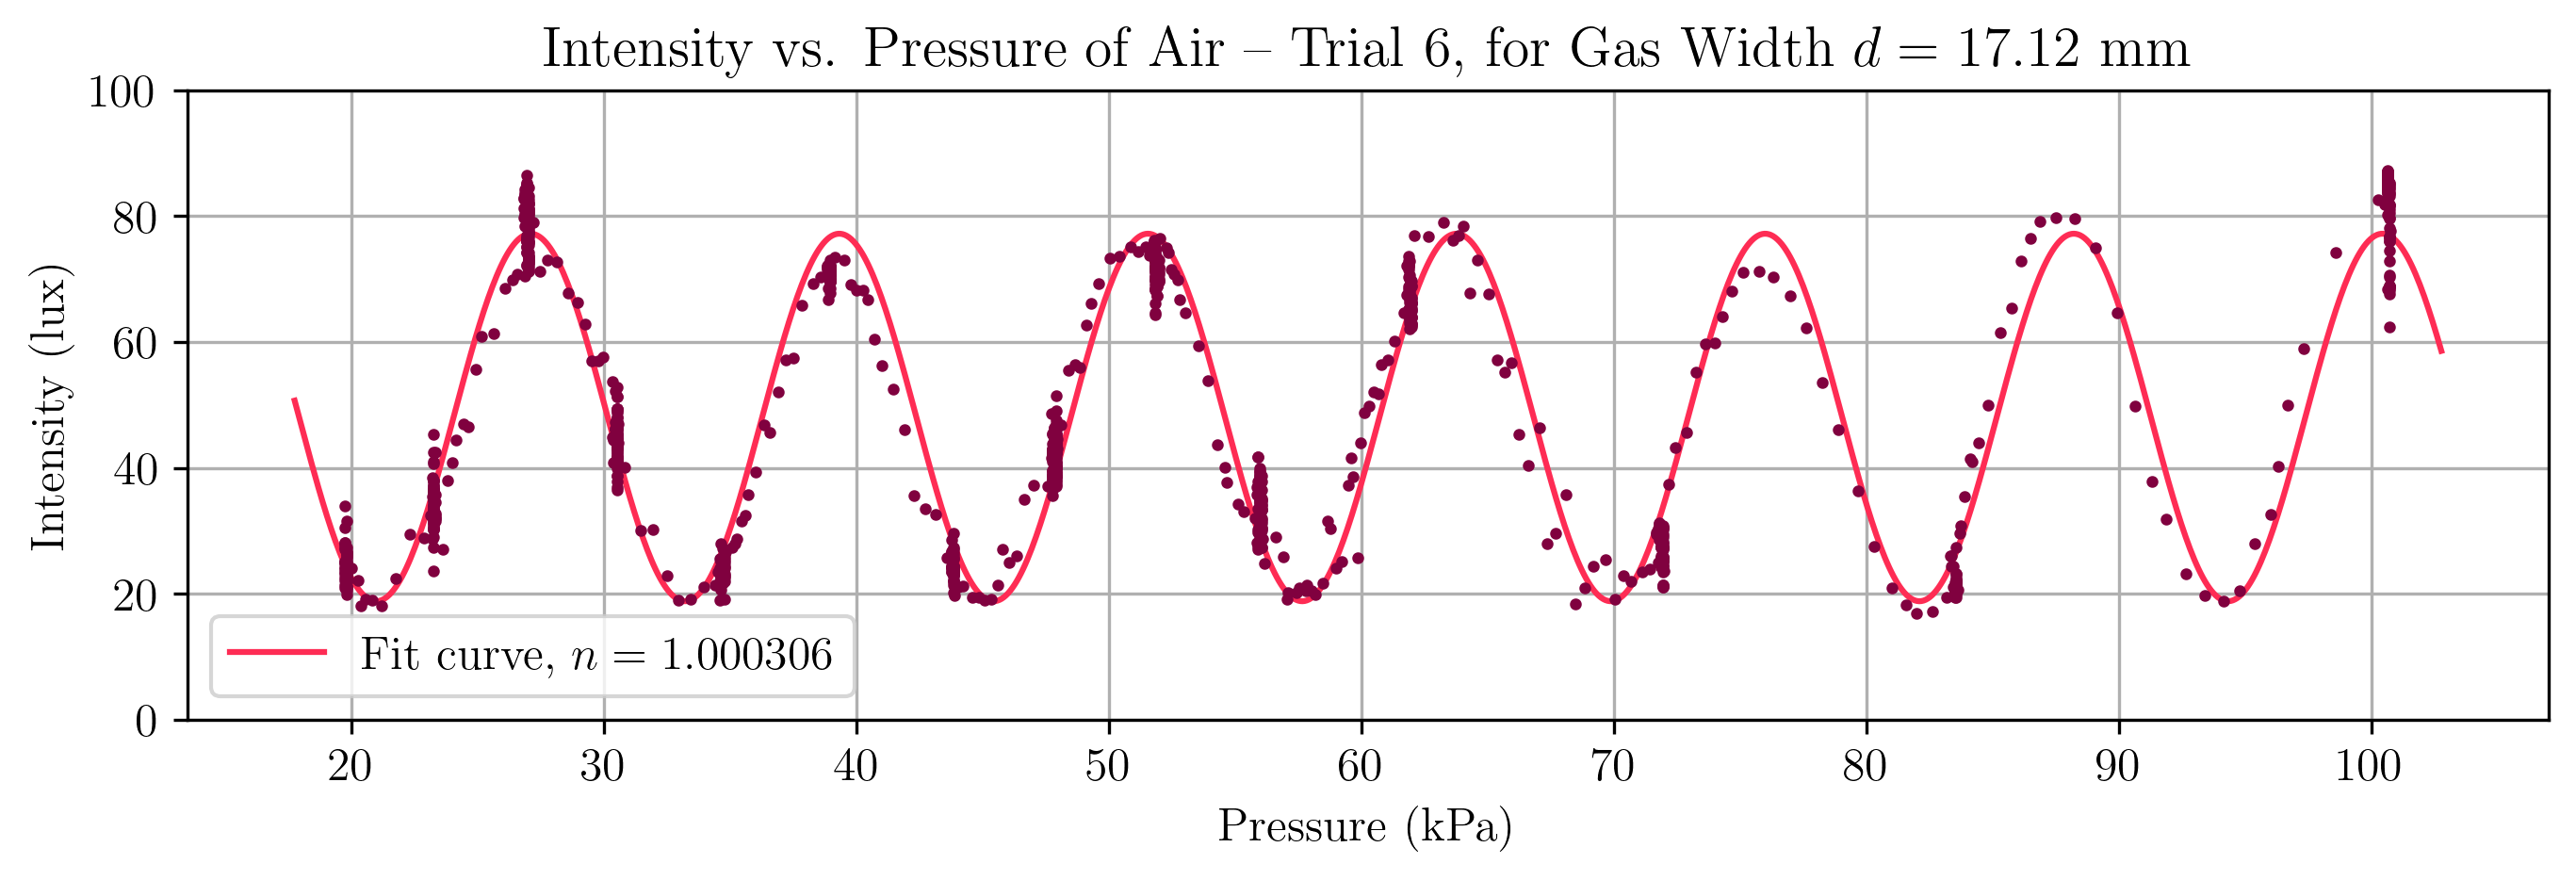

In [85]:
for i in range(len(trial_pressures)):
    if(trial_numbers[i] != 6):
        continue
    pressure = trial_pressures[i]#kpa_per_atm - trial_pressures[i]
    intensity = trial_intensities[i]
    intensity_err = trial_intensities_err[i]

    fit_bounds = scipy.optimize.Bounds(lb=[0, 0, 0, 0], ub=[100, 1e-5, 2*np.pi, 100])

    def loss_function(params, P, I):
        I_calc = fit_curve(P, *params)
        return np.sum((I - I_calc) ** 2)

    course_fit_params = scipy.optimize.differential_evolution(loss_function, bounds=fit_bounds, args=(pressure, intensity))

    popt, pcov = scipy.optimize.curve_fit(fit_curve, pressure, intensity, p0 = course_fit_params.x, bounds=fit_bounds, maxfev=10000)
    I0, k, phi, C = popt
    n = 1 + k * kpa_per_atm
    #print(popt)
    print(n)



    fig, ax = plt.subplots(1, figsize=(9, 3), layout='constrained')

    ax.set_xlabel("Pressure (kPa)")
    ax.set_ylabel("Intensity (lux)")
    ax.set_title(rf"Intensity vs. Pressure of Air -- Trial {trial_numbers[i]}, for Gas Width $d = {gas_width*1e3:0.2f}$ mm")

    ax.xaxis.set_major_locator(ticker.MultipleLocator(10))
    ax.set_ylim(0, 100)

    ax.errorbar(pressure, intensity, intensity_err, color = 'xkcd:wine', markersize=2, fmt='o', capsize=0, zorder=10)

    xvals = np.linspace(min(pressure) - 2, max(pressure) + 2, 1000)
    ax.plot(xvals, fit_curve(xvals, *popt), color = 'xkcd:reddish pink', label = rf"Fit curve, $n = {n:0.6f}$", linewidth=1.5)


    ax.legend()

    fig.savefig("plots/air_trial_4_data.png", dpi=400)